# 9 WorkFlow Analista Jr

### 9.1 Objetivo

Presentar un workflow/pipeline completo al que los estudiantes deberán
<br>El Analista Jr corre sus scripts en la virtual manchine **desktop-jr** que tiene estas características


*   Normal, paga tarifa completa, nunca es apagada por Google
*   reside en el datacenter de Toronto, Canada
*   64 GB de memoria RAM
*   8 vCPU


En Analista Jr **no** puede utilizar Google Colab porque los 12 GB de dichas maquinas virtuales no son suficientes para el tamaño del dataset que está utilizando.



## 9.3  Workflow

## Inicializacion

Esta parte se debe correr con el runtime en lenguaje **R** Ir al menu, Runtime -> Change Runtime Type -> Runtime type -> R

limpio el ambiente de R

In [1]:
format(Sys.time(), "%a %b %d %X %Y")

[1] "Wed Nov 04 23:02:11 2026"

In [2]:
# limpio la memoria
rm(list=ls(all.names=TRUE)) # remove all objects
gc(full=TRUE, verbose=FALSE) # garbage collection

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,671197,35.9,1479650,79.1,1479650,79.1
Vcells,1242599,9.5,8388608,64.0,1978693,15.1


In [3]:
require("data.table")

if( !require("R.utils")) install.packages("R.utils")
require("R.utils")

Loading required package: data.table


Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%


Loading required package: R.utils

Loading required package: R.oo

Loading required package: R.methodsS3

R.methodsS3 v1.8.2 (2022-06-13 22:00:14 UTC) successfully loaded. See ?R.methodsS3 for help.

R.oo v1.27.1 (2025-05-02 21:00:05 UTC) successfully loaded. See ?R.oo for help.


Attaching package: ‘R.oo’


The following object is masked from ‘package:R.methodsS3’:

    throw


The following objects are masked from ‘package:methods’:

    getClasses, getMethods


The following objects are masked from ‘package:base’:

    attach, detach, load, save


R.utils v2.13.0 (2025-02-24 21:20:02 UTC) successfully loaded. See ?R.utils for help.


Attaching package: ‘R.utils’


The following object is masked from ‘package:utils’:

    timestamp


The following objects are masked from ‘package:base’:

    cat, commandArgs, getOption, isOpen, nullfile, parse, u

#### Parametros

In [4]:
PARAM <- list()

# ==========================================
# PARAMETROS DE EJECUCION - GRUPO B (corrida final a Kaggle, SIN notebook maestra)
# ==========================================

PARAM$semilla_primigenia <- 770503
PARAM$experimento <- 9301

# configuracion de Feature Engineering: "E1", "E2", "E3" o "E4"
PARAM$configuracion <- "E4"

# FALSE = corrida completa (con entrenamiento)
PARAM$modo_prueba <- FALSE

# cantidad de semillas del semillerio (se define aca para que figure en el nombre de la carpeta)
# poner este valor en 5 o en 1  si se está muy ajustado de tiempo
PARAM$FT$semillerio <- 30

# identificador de la carpeta de resultados de esta corrida
PARAM$id_ejecucion <- paste0(
  "F_", PARAM$configuracion, "_S", PARAM$semilla_primigenia,
  "_semillerio", PARAM$FT$semillerio
)

# Parametros comunes del workflow
PARAM$dataset <- "analistajr_competencia_2026.csv.gz"

cat("Configuracion:", PARAM$configuracion, "\n")
cat("Semilla:", PARAM$semilla_primigenia, "\n")
cat("Modo prueba:", PARAM$modo_prueba, "\n")
cat("ID:", PARAM$id_ejecucion, "\n")

# momento de inicio, para el respaldo de tiempos del final
t_inicio <- Sys.time()


Configuracion: E4 
Semilla: 770503 
Modo prueba: FALSE 
ID: F_E4_S770503_semillerio30 


#### Carpeta del Experimento

In [5]:
# carpeta de trabajo

#setwd("/content/buckets/b1/exp")
#experimento_folder <- paste0("WF", PARAM$experimento)
#dir.create(experimento_folder, showWarnings=FALSE)
#setwd( paste0("/content/buckets/b1/exp/", experimento_folder ))


# ==========================================
# CARPETA DEL EXPERIMENTO - GRUPO B (corrida final a Kaggle)
# ==========================================

# Ruta base
ruta_base <- "/content/buckets/b1/exp"

# Carpeta de las corridas finales del Grupo B
ruta_final <- file.path(ruta_base, "GrupoB", "Final")

# Carpeta individual de la corrida (configuracion + semilla)
ruta_corrida <- file.path(
  ruta_final,
  PARAM$id_ejecucion
)

# Crear todas las carpetas necesarias
dir.create(
  ruta_corrida,
  recursive = TRUE,
  showWarnings = FALSE
)

# Establecer la carpeta de trabajo
setwd(ruta_corrida)

# Mostrar la ruta utilizada
cat("Carpeta de resultados:", getwd(), "\n")


Carpeta de resultados: /home/ds/buckets/b1/exp/GrupoB/Final/F_E4_S770503_semillerio30 


### 9.3.1   Preprocesamiento del dataset

#### 9.3.1.1  DT incorporar dataset

In [6]:
# lectura del dataset
dataset <- fread(paste0("/content/datasets/", PARAM$dataset))

#### 9.3.1.2  CA  Catastrophe Analysis
Se intentan reparar las variables que para un mes están con todos los valores en cero.

El método que se utiliza es **Machine Learning** se asigna NA also valores, si ha leido bien, es la "anti imputación de valores faltantes"
<br> Usted podrá aplicar aquí otros métodos

In [7]:
if( !require("mice")) install.packages("mice", repos = "http://cran.us.r-project.org")
require("mice")

Loading required package: mice


Attaching package: ‘mice’


The following object is masked from ‘package:stats’:

    filter


The following objects are masked from ‘package:base’:

    cbind, rbind




In [8]:
# Escrito por alumnos de  Universidad Austral  Rosario

Corregir_MICE <- function(pcampo, pmeses) {

  meth <- rep("", ncol(dataset))
  names(meth) <- colnames(dataset)
  meth[names(meth) == pcampo] <- "sample"

  # llamada a mice  !
  imputacion <- mice(dataset,
    method = meth,
    maxit = 5,
    m = 1,
    seed = 7)

  tbl <- mice::complete(dataset)

  dataset[, paste0(pcampo) := ifelse(foto_mes %in% pmeses, tbl[, get(pcampo)], get(pcampo))]

}


In [9]:
Corregir_interpolar <- function(pcampo, pmeses) {

  tbl <- dataset[, list(
    "v1" = shift(get(pcampo), 1, type = "lag"),
    "v2" = shift(get(pcampo), 1, type = "lead")
  ),
  by = eval(envg$PARAM$dataset_metadata$entity_id)
  ]

  tbl[, paste0(envg$PARAM$dataset_metadata$entity_id) := NULL]
  tbl[, promedio := rowMeans(tbl, na.rm = TRUE)]

  dataset[
    ,
    paste0(pcampo) := ifelse(!(foto_mes %in% pmeses),
      get(pcampo),
      tbl$promedio
    )
  ]
}

In [10]:
AsignarNA_campomeses <- function(pcampo, pmeses) {

  if( pcampo %in% colnames( dataset ) ) {

    dataset[ foto_mes %in% pmeses, paste0(pcampo) := NA ]
  }
}

In [11]:

Corregir_atributo <- function(pcampo, pmeses, pmetodo)
{
  # si el campo no existe en el dataset, Afuera !
  if( !(pcampo %in% colnames( dataset )) )
    return( 1 )

  # llamo a la funcion especializada que corresponde
  switch( pmetodo,
    "MachineLearning"     = AsignarNA_campomeses(pcampo, pmeses),
    "EstadisticaClasica"  = Corregir_interpolar(pcampo, pmeses),
    "MICE"                = Corregir_MICE(pcampo, pmeses),
  )

  return( 0 )
}

In [12]:

Corregir_Rotas <- function(dataset, pmetodo) {
  gc(verbose= FALSE)
  cat( "inicio Corregir_Rotas()\n")
  # acomodo los errores del dataset

  Corregir_atributo("active_quarter", c(202006), pmetodo) # 1
  Corregir_atributo("internet", c(202006), pmetodo) # 2

  Corregir_atributo("mrentabilidad", c(201905, 201910, 202006), pmetodo) # 3
  Corregir_atributo("mrentabilidad_annual", c(201905, 201910, 202006), pmetodo) # 4

  Corregir_atributo("mcomisiones", c(201905, 201910, 202006), pmetodo) # 5

  Corregir_atributo("mactivos_margen", c(201905, 201910, 202006), pmetodo) # 6
  Corregir_atributo("mpasivos_margen", c(201905, 201910, 202006), pmetodo) # 7

  Corregir_atributo("mcuentas_saldo", c(202006), pmetodo) # 8

  Corregir_atributo("ctarjeta_debito_transacciones", c(202006), pmetodo) # 9

  Corregir_atributo("mautoservicio", c(202006), pmetodo) # 10

  Corregir_atributo("ctarjeta_visa_transacciones", c(202006), pmetodo) # 11
  Corregir_atributo("mtarjeta_visa_consumo", c(202006), pmetodo) # 12

  Corregir_atributo("ctarjeta_master_transacciones", c(202006), pmetodo) # 13
  Corregir_atributo("mtarjeta_master_consumo", c(202006), pmetodo) # 14

  Corregir_atributo("ctarjeta_visa_debitos_automaticos", c(201904), pmetodo) # 15
  Corregir_atributo("mttarjeta_visa_debitos_automaticos", c(201904), pmetodo) # 16

  Corregir_atributo("ccajeros_propios_descuentos",
    c(201910, 202002, 202006, 202009, 202010, 202102), pmetodo) # 17

  Corregir_atributo("mcajeros_propios_descuentos",
    c(201910, 202002, 202006, 202009, 202010, 202102), pmetodo) # 18

  Corregir_atributo("ctarjeta_visa_descuentos",
    c(201910, 202002, 202006, 202009, 202010, 202102), pmetodo) # 19

  Corregir_atributo("mtarjeta_visa_descuentos",
    c(201910, 202002, 202006, 202009, 202010, 202102), pmetodo) # 20

  Corregir_atributo("ctarjeta_master_descuentos",
    c(201910, 202002, 202006, 202009, 202010, 202102), pmetodo) # 21

  Corregir_atributo("mtarjeta_master_descuentos",
    c(201910, 202002, 202006, 202009, 202010, 202102), pmetodo) # 22

  Corregir_atributo("ccomisiones_otras", c(201905, 201910, 202006), pmetodo) # 23
  Corregir_atributo("mcomisiones_otras", c(201905, 201910, 202006), pmetodo) # 24

  Corregir_atributo("cextraccion_autoservicio", c(202006), pmetodo) # 25
  Corregir_atributo("mextraccion_autoservicio", c(202006), pmetodo) # 26

  Corregir_atributo("ccheques_depositados", c(202006), pmetodo) # 27
  Corregir_atributo("mcheques_depositados", c(202006), pmetodo) # 28
  Corregir_atributo("ccheques_emitidos", c(202006), pmetodo) # 29
  Corregir_atributo("mcheques_emitidos", c(202006), pmetodo) # 30
  Corregir_atributo("ccheques_depositados_rechazados", c(202006), pmetodo) # 31
  Corregir_atributo("mcheques_depositados_rechazados", c(202006), pmetodo) # 32
  Corregir_atributo("ccheques_emitidos_rechazados", c(202006), pmetodo) # 33
  Corregir_atributo("mcheques_emitidos_rechazados", c(202006), pmetodo) # 34

  Corregir_atributo("tcallcenter", c(202006), pmetodo) # 35
  Corregir_atributo("ccallcenter_transacciones", c(202006), pmetodo) # 36

  Corregir_atributo("thomebanking", c(202006), pmetodo) # 37
  Corregir_atributo("chomebanking_transacciones", c(201910, 202006), pmetodo) # 38

  Corregir_atributo("ccajas_transacciones", c(202006), pmetodo) # 39
  Corregir_atributo("ccajas_consultas", c(202006), pmetodo) # 40

  Corregir_atributo("ccajas_depositos", c(202006, 202105), pmetodo) # 41

  Corregir_atributo("ccajas_extracciones", c(202006), pmetodo) # 41
  Corregir_atributo("ccajas_otras", c(202006), pmetodo) # 43

  Corregir_atributo("catm_trx", c(202006), pmetodo) # 44
  Corregir_atributo("matm", c(202006), pmetodo) # 45
  Corregir_atributo("catm_trx_other", c(202006), pmetodo) # 46
  Corregir_atributo("matm_other", c(202006), pmetodo) # 47

  cat( "fin Corregir_rotas()\n")
}


In [13]:
# resuelvo el Catastrophe Analysis

setorder( dataset, numero_de_cliente, foto_mes )

PARAM$CA$metodo= "MachineLearning"

if( PARAM$CA$metodo %in% c("MachineLearning", "EstadisticaClasica", "MICE") )
  Corregir_Rotas(dataset, PARAM$CA$metodo)

inicio Corregir_Rotas()
fin Corregir_rotas()


#### 9.3.1.3  DR  Data Drifting
Se intenta corregir el data drifting, ajustando por algunos indices financieros

In [14]:
# meses que me interesan para el ajuste de variables monetarias
vfoto_mes <- c(
  201901, 201902, 201903, 201904, 201905, 201906,
  201907, 201908, 201909, 201910, 201911, 201912,
  202001, 202002, 202003, 202004, 202005, 202006,
  202007, 202008, 202009, 202010, 202011, 202012,
  202101, 202102, 202103, 202104, 202105, 202106,
  202107, 202108, 202109
)


In [15]:
# los valores que siguen fueron calculados por alumnos

# momento 1.0  31-dic-2020 a las 23:59
vIPC <- c(
  1.9903030878, 1.9174403544, 1.8296186587,
  1.7728862972, 1.7212488323, 1.6776304408,
  1.6431248196, 1.5814483345, 1.4947526791,
  1.4484037589, 1.3913580777, 1.3404220402,
  1.3154288912, 1.2921698342, 1.2472681797,
  1.2300475145, 1.2118694724, 1.1881073259,
  1.1693969743, 1.1375456949, 1.1065619600,
  1.0681100000, 1.0370000000, 1.0000000000,
  0.9680542110, 0.9344152616, 0.8882274350,
  0.8532444140, 0.8251880213, 0.8003763543,
  0.7763107219, 0.7566381305, 0.7289384687
)

vdolar_blue <- c(
   39.045455,  38.402500,  41.639474,
   44.274737,  46.095455,  45.063333,
   43.983333,  54.842857,  61.059524,
   65.545455,  66.750000,  72.368421,
   77.477273,  78.191667,  82.434211,
  101.087500, 126.236842, 125.857143,
  130.782609, 133.400000, 137.954545,
  170.619048, 160.400000, 153.052632,
  157.900000, 149.380952, 143.615385,
  146.250000, 153.550000, 162.000000,
  178.478261, 180.878788, 184.357143
)

vdolar_oficial <- c(
   38.430000,  39.428000,  42.542105,
   44.354211,  46.088636,  44.955000,
   43.751429,  54.650476,  58.790000,
   61.403182,  63.012632,  63.011579,
   62.983636,  63.580556,  65.200000,
   67.872000,  70.047895,  72.520952,
   75.324286,  77.488500,  79.430909,
   83.134762,  85.484737,  88.181667,
   91.474000,  93.997778,  96.635909,
   98.526000,  99.613158, 100.619048,
  101.619048, 102.569048, 103.781818
)

vUVA <- c(
  2.001408838932958,  1.950325472789153,  1.89323032351521,
  1.8247220405493787, 1.746027787673673,  1.6871348409529485,
  1.6361678865622313, 1.5927529755859773, 1.5549162794128493,
  1.4949100586391746, 1.4197729500774545, 1.3678188186372326,
  1.3136508617223726, 1.2690535173062818, 1.2381595983200178,
  1.211656735577568,  1.1770808941405335, 1.1570338657445522,
  1.1388769475653255, 1.1156993751209352, 1.093638313080772,
  1.0657171590878205, 1.0362173587708712, 1.0,
  0.9669867858358365, 0.9323750098728378, 0.8958202912590305,
  0.8631993702994263, 0.8253893405524657, 0.7928918905364516,
  0.7666323845128089, 0.7428976357662823, 0.721615762047849
)


In [16]:
tb_indices <- as.data.table( list(
  "IPC" = vIPC,
  "dolar_blue" = vdolar_blue,
  "dolar_oficial" = vdolar_oficial,
  "UVA" = vUVA
  )
)

tb_indices[[ 'foto_mes' ]] <- vfoto_mes

tb_indices

IPC,dolar_blue,dolar_oficial,UVA,foto_mes
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1.9903031,39.04545,38.43000,2.0014088,201901
1.9174404,38.40250,39.42800,1.9503255,201902
1.8296187,41.63947,42.54210,1.8932303,201903
1.7728863,44.27474,44.35421,1.8247220,201904
1.7212488,46.09546,46.08864,1.7460278,201905
1.6776304,45.06333,44.95500,1.6871348,201906
1.6431248,43.98333,43.75143,1.6361679,201907
1.5814483,54.84286,54.65048,1.5927530,201908
1.4947527,61.05952,58.79000,1.5549163,201909


In [17]:
drift_UVA <- function(campos_monetarios) {
  cat( "inicio drift_UVA()\n")

  dataset[tb_indices,
    on = c("foto_mes"),
    (campos_monetarios) := .SD * i.UVA,
    .SDcols = campos_monetarios
  ]

  cat( "fin drift_UVA()\n")
}


In [18]:
drift_dolar_oficial <- function(campos_monetarios) {
  cat( "inicio drift_dolar_oficial()\n")

  dataset[tb_indices,
    on = c("foto_mes"),
    (campos_monetarios) := .SD / i.dolar_oficial,
    .SDcols = campos_monetarios
  ]

  cat( "fin drift_dolar_oficial()\n")
}


In [19]:
drift_dolar_blue <- function(campos_monetarios) {
  cat( "inicio drift_dolar_blue()\n")

  dataset[tb_indices,
    on = c("foto_mes"),
    (campos_monetarios) := .SD / i.dolar_blue,
    .SDcols = campos_monetarios
  ]

  cat( "fin drift_dolar_blue()\n")
}


In [20]:
drift_deflacion <- function(campos_monetarios) {
  cat( "inicio drift_deflacion()\n")

  dataset[tb_indices,
    on = c("foto_mes"),
    (campos_monetarios) := .SD * i.IPC,
    .SDcols = campos_monetarios
  ]

  cat( "fin drift_deflacion()\n")
}


In [21]:
drift_rank_simple <- function(campos_drift) {

  cat( "inicio drift_rank_simple()\n")
  for (campo in campos_drift)
  {
    cat(campo, " ")
    dataset[, paste0(campo, "_rank") :=
      (frank(get(campo), ties.method = "random") - 1) / (.N - 1), by = list(foto_mes)]
    dataset[, (campo) := NULL]
  }
  cat( "fin drift_rank_simple()\n")
}


In [22]:
# El cero se transforma en cero
# los positivos se rankean por su lado
# los negativos se rankean por su lado

drift_rank_cero_fijo <- function(campos_drift) {

  cat( "inicio drift_rank_cero_fijo()\n")
  for (campo in campos_drift)
  {
    cat(campo, " ")
    dataset[get(campo) == 0, paste0(campo, "_rank") := 0]
    dataset[get(campo) > 0, paste0(campo, "_rank") :=
      frank(get(campo), ties.method = "random") / .N, by = list(foto_mes)]

    dataset[get(campo) < 0, paste0(campo, "_rank") :=
      -frank(-get(campo), ties.method = "random") / .N, by = list(foto_mes)]
    dataset[, (campo) := NULL]
  }
  cat("\n")
  cat( "fin drift_rank_cero_fijo()\n")
}


In [23]:
# funcion provista por alumnos amantes de la Estadistica Clasica

drift_estandarizar <- function(campos_drift) {

  cat( "inicio drift_estandarizar()\n")
  for (campo in campos_drift)
  {
    cat(campo, " ")
    dataset[, paste0(campo, "_normal") :=
      (get(campo) -mean(get(campo), na.rm=TRUE)) / sd(get(campo), na.rm=TRUE),
      by = list(foto_mes)]

    dataset[, (campo) := NULL]
  }
  cat( "fin drift_estandarizar()\n")
}


In [24]:
# por como armé los nombres de campos,
#  estos son los campos que expresan variables monetarias
campos_monetarios <- colnames(dataset)
campos_monetarios <- campos_monetarios[campos_monetarios %like%
  "^(m|Visa_m|Master_m|vm_m)"]

campos_monetarios

[1] "mrentabilidad"                      "mrentabilidad_annual"              
 [3] "mcomisiones"                        "mactivos_margen"                   
 [5] "mpasivos_margen"                    "mcuenta_corriente"                 
 [7] "mcaja_ahorro"                       "mcuentas_saldo"                    
 [9] "mtarjeta_visa_consumo"              "mtarjeta_master_consumo"           
[11] "mprestamos_personales"              "mpayroll"                          
[13] "mttarjeta_visa_debitos_automaticos" "mcomisiones_mantenimiento"         
[15] "mtransferencias_recibidas"          "Master_mfinanciacion_limite"       
[17] "Master_msaldototal"                 "Master_mlimitecompra"              
[19] "Master_mconsumototal"               "Master_mpagominimo"                
[21] "Visa_mfinanciacion_limite"          "Visa_msaldototal"                  
[23] "Visa_mlimitecompra"                 "Visa_mconsumototal"                
[25] "Visa_mpagominimo"

In [25]:
# ejecuto el Data Drifting
setorder( dataset, numero_de_cliente, foto_mes )


PARAM$DR$metodo <- "deflacion"

switch(PARAM$DR$metodo,
  "ninguno"        = cat("No hay correccion del data drifting"),
  "rank_simple"    = drift_rank_simple(campos_monetarios),
  "rank_cero_fijo" = drift_rank_cero_fijo(campos_monetarios),
  "deflacion"      = drift_deflacion(campos_monetarios),
  "dolar_blue"     = drift_dolarblue(campos_monetarios),
  "dolar_oficial"  = drift_dolaroficial(campos_monetarios),
  "UVA"            = drift_UVA(campos_monetarios),
  "estandarizar"   = drift_estandarizar(campos_monetarios)
)


inicio drift_deflacion()
fin drift_deflacion()


In [26]:
colnames(dataset)

[1] "numero_de_cliente"                  "foto_mes"                          
 [3] "internet"                           "cliente_edad"                      
 [5] "cliente_antiguedad"                 "mrentabilidad"                     
 [7] "mrentabilidad_annual"               "mcomisiones"                       
 [9] "mactivos_margen"                    "mpasivos_margen"                   
[11] "cproductos"                         "mcuenta_corriente"                 
[13] "mcaja_ahorro"                       "cdescubierto_preacordado"          
[15] "mcuentas_saldo"                     "ctarjeta_visa"                     
[17] "ctarjeta_visa_transacciones"        "mtarjeta_visa_consumo"             
[19] "ctarjeta_master"                    "ctarjeta_master_transacciones"     
[21] "mtarjeta_master_consumo"            "cprestamos_personales"             
[23] "mprestamos_personales"              "cpayroll_trx"                      
[25] "mpayroll"                           "mttarjeta_visa_debitos_automaticos"
[27] "ccomisiones_mantenimiento"          "mcomisiones_mantenimiento"         
[29] "ccomisiones_otras"                  "mtransferencias_recibidas"         
[31] "ccallcenter_transacciones"          "thomebanking"                      
[33] "chomebanking_transacciones"         "ctrx_quarter"                      
[35] "Master_status"                      "Master_mfinanciacion_limite"       
[37] "Master_Fvencimiento"                "Master_msaldototal"                
[39] "Master_mlimitecompra"               "Master_fultimo_cierre"             
[41] "Master_fechaalta"                   "Master_mconsumototal"              
[43] "Master_cconsumos"                   "Master_mpagominimo"                
[45] "Visa_status"                        "Visa_mfinanciacion_limite"         
[47] "Visa_Fvencimiento"                  "Visa_msaldototal"                  
[49] "Visa_mlimitecompra"                 "Visa_fultimo_cierre"               
[51] "Visa_fechaalta"                     "Visa_mconsumototal"                
[53] "Visa_cconsumos"                     "Visa_mpagominimo"                  
[55] "clase_ternaria"

In [27]:
# se intenta corregir el data drifting utilizando algunos indices financieros

#### 9.3.1.3  FE_intra_manual Feature Engineering intra-mes

Agrego campos nuevos dentro del mismo mes, SIN considerar la historia.

In [28]:
# esta funcion atributos presentes existe debido a que las modalidades poseen datasets con distinta cantidad de campos
atributos_presentes <- function( patributos )
{
  atributos <- unique( patributos )
  comun <- intersect( atributos, colnames(dataset) )

  return(  length( atributos ) == length( comun ) )
}

# el mes 1,2, ..12
if( atributos_presentes( c("foto_mes") ))
  dataset[, kmes := foto_mes %% 100]

# variable extraida de una tesis de maestria de Irlanda
if( atributos_presentes( c("mpayroll", "cliente_edad") ))
  dataset[, mpayroll_sobre_edad := mpayroll / cliente_edad]


In [29]:
# visualizo las columas del dataset a esta etapa
colnames(dataset)

[1] "numero_de_cliente"                  "foto_mes"                          
 [3] "internet"                           "cliente_edad"                      
 [5] "cliente_antiguedad"                 "mrentabilidad"                     
 [7] "mrentabilidad_annual"               "mcomisiones"                       
 [9] "mactivos_margen"                    "mpasivos_margen"                   
[11] "cproductos"                         "mcuenta_corriente"                 
[13] "mcaja_ahorro"                       "cdescubierto_preacordado"          
[15] "mcuentas_saldo"                     "ctarjeta_visa"                     
[17] "ctarjeta_visa_transacciones"        "mtarjeta_visa_consumo"             
[19] "ctarjeta_master"                    "ctarjeta_master_transacciones"     
[21] "mtarjeta_master_consumo"            "cprestamos_personales"             
[23] "mprestamos_personales"              "cpayroll_trx"                      
[25] "mpayroll"                           "mttarjeta_visa_debitos_automaticos"
[27] "ccomisiones_mantenimiento"          "mcomisiones_mantenimiento"         
[29] "ccomisiones_otras"                  "mtransferencias_recibidas"         
[31] "ccallcenter_transacciones"          "thomebanking"                      
[33] "chomebanking_transacciones"         "ctrx_quarter"                      
[35] "Master_status"                      "Master_mfinanciacion_limite"       
[37] "Master_Fvencimiento"                "Master_msaldototal"                
[39] "Master_mlimitecompra"               "Master_fultimo_cierre"             
[41] "Master_fechaalta"                   "Master_mconsumototal"              
[43] "Master_cconsumos"                   "Master_mpagominimo"                
[45] "Visa_status"                        "Visa_mfinanciacion_limite"         
[47] "Visa_Fvencimiento"                  "Visa_msaldototal"                  
[49] "Visa_mlimitecompra"                 "Visa_fultimo_cierre"               
[51] "Visa_fechaalta"                     "Visa_mconsumototal"                
[53] "Visa_cconsumos"                     "Visa_mpagominimo"                  
[55] "clase_ternaria"                     "kmes"                              
[57] "mpayroll_sobre_edad"

#### 9.3.1.4  FE_rf Feature Engineering de nuevas variables a partir de hojas de Random Forest

In [30]:
# No se implementa Feature Engineering a partir de Random Forest

#### 9.3.1.5  FEhist Feature Engineering historico

El Fature Engineering Histórico es la etapa que más aporta a la ganancia final, ya que enriquece cada registro del dataset con su historia.

Para cada campo del dataset original (*)
se crean lo siguientes campos de a partir de la historia
* lag1  lags de orden 1
* delta1  =  valor actual - lag1
* lag2  lags de orden 2
* delta2  = valor actual - lag2


(*) Excepto para los campos  <numero_de_cliente,  foto_mes,  clase_ternaria>

In [31]:
# Feature Engineering Historico

# todo es lagueable, menos la primary key y la clase
cols_lagueables <- copy( setdiff(
    colnames(dataset),
    c("numero_de_cliente", "foto_mes", "clase_ternaria")
) )

# https://rdrr.io/cran/data.table/man/shift.html

# lags de orden 1
dataset[,
    paste0(cols_lagueables, "_lag1") := shift(.SD, 1, NA, "lag"),
    by = numero_de_cliente,
    .SDcols = cols_lagueables
]

# lags de orden 2
dataset[,
    paste0(cols_lagueables, "_lag2") := shift(.SD, 2, NA, "lag"),
    by = numero_de_cliente,
    .SDcols = cols_lagueables
]

# agrego los delta lags
for (vcol in cols_lagueables)
{
    dataset[, paste0(vcol, "_delta1") := get(vcol) - get(paste0(vcol, "_lag1"))]
    dataset[, paste0(vcol, "_delta2") := get(vcol) - get(paste0(vcol, "_lag2"))]
}


# ==========================================
# FEATURE ENGINEERING ADICIONAL - GRUPO B
# ==========================================

# E1 y E4: incorporar lag3 y lag4
if (PARAM$configuracion %in% c("E1", "E4")) {

  for (n in c(3, 4)) {

    dataset[
      , paste0(cols_lagueables, "_lag", n) :=
        shift(.SD, n, NA, "lag"),
      by = numero_de_cliente,
      .SDcols = cols_lagueables
    ]

  }

}

# ==========================================
# VARIABLES CANDIDATAS PARA E2 Y E3
# ==========================================

if (PARAM$configuracion %in% c("E2", "E3", "E4")) {

  # Seleccionar variables originales numericas
  variables_e2_e3 <- cols_lagueables[
    sapply(dataset[, ..cols_lagueables], is.numeric)
  ]

  # Excluir variables sin interpretacion
  # adecuada para tendencias y medias moviles
  excluir <- c(
    "cliente_edad",
    "cliente_antiguedad",
    "kmes"
  )

  variables_e2_e3 <- setdiff(
    variables_e2_e3,
    excluir
  )

  # Mostrar la seleccion para revisarla
  cat("Cantidad seleccionada:",
      length(variables_e2_e3), "\n")

  print(variables_e2_e3)

}



# ==========================================
# E2 y E4 - TENDENCIAS HISTORICAS
# ==========================================

if (PARAM$configuracion %in% c("E2", "E4")) {

  for (vcol in variables_e2_e3) {

    actual <- dataset[[vcol]]

    # lag1 y lag2 ya fueron creados arriba para todas las configuraciones
    lag1 <- dataset[[paste0(vcol, "_lag1")]]
    lag2 <- dataset[[paste0(vcol, "_lag2")]]

    # lag3: en E4 ya existe; en E2 se calcula una sola vez
    nm3 <- paste0(vcol, "_lag3")
    if (nm3 %in% names(dataset)) {
      lag3 <- dataset[[nm3]]
    } else {
      lag3 <- dataset[, shift(get(vcol), 3L), by = numero_de_cliente]$V1
    }

    # Variacion acumulada respecto de tres periodos atras
    dataset[, paste0(vcol, "_variacion3") := actual - lag3]

    # Cantidad de disminuciones entre observaciones
    dataset[, paste0(vcol, "_caidas3") :=
      as.integer(actual < lag1) +
      as.integer(lag1 < lag2) +
      as.integer(lag2 < lag3)]

    # Pendiente de tendencia (minimos cuadrados) de cuatro observaciones
    dataset[, paste0(vcol, "_pendiente3") :=
      (-1.5 * lag3 - 0.5 * lag2 + 0.5 * lag1 + 1.5 * actual) / 5]

  }
}


# ==========================================
# E3 y E4 - MEDIAS MOVILES Y ESTABILIDAD
# ==========================================

if (PARAM$configuracion %in% c("E3", "E4")) {

  for (vcol in variables_e2_e3) {

    tmp_a  <- dataset[[vcol]]
    tmp_l1 <- dataset[[paste0(vcol, "_lag1")]]
    tmp_l2 <- dataset[[paste0(vcol, "_lag2")]]

    # Media movil de 3 observaciones (actual, lag1, lag2)
    tmp_m3 <- (tmp_a + tmp_l1 + tmp_l2) / 3
    dataset[, paste0(vcol, "_media_movil3") := tmp_m3]

    # Desvio estandar de las ultimas 3 observaciones (vectorizado, equivale a sd())
    dataset[, paste0(vcol, "_desvio_movil3") :=
      sqrt(((tmp_a - tmp_m3)^2 + (tmp_l1 - tmp_m3)^2 + (tmp_l2 - tmp_m3)^2) / 2)]

    # Media movil de 6 observaciones
    dataset[, paste0(vcol, "_media_movil6") :=
      frollmean(get(vcol), 6, align = "right"),
      by = numero_de_cliente]

  }
}


Cantidad seleccionada: 51 
 [1] "internet"                           "mrentabilidad"                     
 [3] "mrentabilidad_annual"               "mcomisiones"                       
 [5] "mactivos_margen"                    "mpasivos_margen"                   
 [7] "cproductos"                         "mcuenta_corriente"                 
 [9] "mcaja_ahorro"                       "cdescubierto_preacordado"          
[11] "mcuentas_saldo"                     "ctarjeta_visa"                     
[13] "ctarjeta_visa_transacciones"        "mtarjeta_visa_consumo"             
[15] "ctarjeta_master"                    "ctarjeta_master_transacciones"     
[17] "mtarjeta_master_consumo"            "cprestamos_personales"             
[19] "mprestamos_personales"              "cpayroll_trx"                      
[21] "mpayroll"                           "mttarjeta_visa_debitos_automaticos"
[23] "ccomisiones_mantenimiento"          "mcomisiones_mantenimiento"         
[25] "ccomisiones_otras" 

Verificacion de los campos recien creados

In [32]:
# ==========================================
# VERIFICACION FEATURE ENGINEERING - GRUPO B
# ==========================================

# Controles originales
ncol(dataset)
colnames(dataset)

# Variables nuevas de E1
vars_e1 <- grep(
  "_lag[34]$", names(dataset), value = TRUE
)

# Variables nuevas de E2
vars_e2 <- grep(
  "_(variacion3|caidas3|pendiente3)$",
  names(dataset), value = TRUE
)

# Variables nuevas de E3
vars_e3 <- grep(
  "_(media_movil3|media_movil6|desvio_movil3)$",
  names(dataset), value = TRUE
)

# Resumen
cat("\nConfiguracion:", PARAM$configuracion, "\n")
cat("Total de columnas:", ncol(dataset), "\n")
cat("Variables E1:", length(vars_e1), "\n")
cat("Variables E2:", length(vars_e2), "\n")
cat("Variables E3:", length(vars_e3), "\n")

if (PARAM$configuracion %in% c("E2", "E3", "E4")) {
  cat("\nVARIABLES SELECCIONADAS PARA E2/E3:\n")
  print(variables_e2_e3)
}


if (PARAM$modo_prueba) {

  cat("\n====================================\n")
  cat("PRUEBA TECNICA FINALIZADA\n")
  cat("Configuracion:", PARAM$configuracion, "\n")
  cat("Semilla:", PARAM$semilla_primigenia, "\n")
  cat("Columnas generadas:", ncol(dataset), "\n")
  cat("Entrenamiento: NO EJECUTADO\n")
  cat("====================================\n")

}

[1] 687

[1] "numero_de_cliente"                               
  [2] "foto_mes"                                        
  [3] "internet"                                        
  [4] "cliente_edad"                                    
  [5] "cliente_antiguedad"                              
  [6] "mrentabilidad"                                   
  [7] "mrentabilidad_annual"                            
  [8] "mcomisiones"                                     
  [9] "mactivos_margen"                                 
 [10] "mpasivos_margen"                                 
 [11] "cproductos"                                      
 [12] "mcuenta_corriente"                               
 [13] "mcaja_ahorro"                                    
 [14] "cdescubierto_preacordado"                        
 [15] "mcuentas_saldo"                                  
 [16] "ctarjeta_visa"                                   
 [17] "ctarjeta_visa_transacciones"                     
 [18] "mtarjeta_visa_consumo"                           
 [19] "ctarjeta_master"                                 
 [20] "ctarjeta_master_transacciones"                   
 [21] "mtarjeta_master_consumo"                         
 [22] "cprestamos_personales"                           
 [23] "mprestamos_personales"                           
 [24] "cpayroll_trx"                                    
 [25] "mpayroll"                                        
 [26] "mttarjeta_visa_debitos_automaticos"              
 [27] "ccomisiones_mantenimiento"                       
 [28] "mcomisiones_mantenimiento"                       
 [29] "ccomisiones_otras"                               
 [30] "mtransferencias_recibidas"                       
 [31] "ccallcenter_transacciones"                       
 [32] "thomebanking"                                    
 [33] "chomebanking_transacciones"                      
 [34] "ctrx_quarter"                                    
 [35] "Master_status"                                   
 [36] "Master_mfinanciacion_limite"                     
 [37] "Master_Fvencimiento"                             
 [38] "Master_msaldototal"                              
 [39] "Master_mlimitecompra"                            
 [40] "Master_fultimo_cierre"                           
 [41] "Master_fechaalta"                                
 [42] "Master_mconsumototal"                            
 [43] "Master_cconsumos"                                
 [44] "Master_mpagominimo"                              
 [45] "Visa_status"                                     
 [46] "Visa_mfinanciacion_limite"                       
 [47] "Visa_Fvencimiento"                               
 [48] "Visa_msaldototal"                                
 [49] "Visa_mlimitecompra"                              
 [50] "Visa_fultimo_cierre"                             
 [51] "Visa_fechaalta"                                  
 [52] "Visa_mconsumototal"                              
 [53] "Visa_cconsumos"                                  
 [54] "Visa_mpagominimo"                                
 [55] "clase_ternaria"                                  
 [56] "kmes"                                            
 [57] "mpayroll_sobre_edad"                             
 [58] "internet_lag1"                                   
 [59] "cliente_edad_lag1"                               
 [60] "cliente_antiguedad_lag1"                         
 [61] "mrentabilidad_lag1"                              
 [62] "mrentabilidad_annual_lag1"                       
 [63] "mcomisiones_lag1"                                
 [64] "mactivos_margen_lag1"                            
 [65] "mpasivos_margen_lag1"                            
 [66] "cproductos_lag1"                                 
 [67] "mcuenta_corriente_lag1"                          
 [68] "mcaja_ahorro_lag1"                               
 [69] "cdescubierto_preacordado_lag1"                   
 [70] "mcuentas_saldo_lag1"                             
 [71] "ctarj


Configuracion: E4 
Total de columnas: 687 
Variables E1: 108 
Variables E2: 153 
Variables E3: 153 

VARIABLES SELECCIONADAS PARA E2/E3:
 [1] "internet"                           "mrentabilidad"                     
 [3] "mrentabilidad_annual"               "mcomisiones"                       
 [5] "mactivos_margen"                    "mpasivos_margen"                   
 [7] "cproductos"                         "mcuenta_corriente"                 
 [9] "mcaja_ahorro"                       "cdescubierto_preacordado"          
[11] "mcuentas_saldo"                     "ctarjeta_visa"                     
[13] "ctarjeta_visa_transacciones"        "mtarjeta_visa_consumo"             
[15] "ctarjeta_master"                    "ctarjeta_master_transacciones"     
[17] "mtarjeta_master_consumo"            "cprestamos_personales"             
[19] "mprestamos_personales"              "cpayroll_trx"                      
[21] "mpayroll"                           "mttarjeta_visa_debitos_automa

#### 9.3.1.6  FEhist Reduccion dimensionalidad con canaritos

Esta etapa solo se mostrará a la *modalidad Anlista Sr* por algun canal secreto de forma de no confundir a los *Analista Jr*  ni distraer con detalles operativos a la estratégica *Modalidad Gerencial*

In [33]:
# No se implementa la reduccion de la dimensionalidad con canaritos

### 9.3.2 Modelado

#### 9.3.2.1 Training Strategy

Se hace una estrategia de entrenamiento muy sencilla, tomando todos los meses posibles, SIN eliminar nada x pandemia ni por ningun otro motivo

* future = 202109  obviamente completo

* final_train =  [ 201901, 202107 ]  SIN undersampling

* training
   * testing = NO HAY
   * validation =  202107   completo, sin undersampling
   * training = [ 201901, 202105 ]  donde se consideran el 100% de los CONTINUA

In [34]:
PARAM$trainingstrategy$validate <- c(202107)

PARAM$trainingstrategy$training <- c(
  201901, 201902, 201903, 201904, 201905, 201906,
  201907, 201908, 201909, 201910, 201911, 201912,
  202001, 202002, 202003, 202004, 202005, 202006,
  202007, 202008, 202009, 202010, 202011, 202012,
  202101, 202102, 202103, 202104, 202105
)


PARAM$trainingstrategy$training_pct <- 1.0


PARAM$trainingstrategy$positivos <- c( "BAJA+1", "BAJA+2")

In [35]:
# seteo la clase01   1={BAJA+1, BAJA+2}   0={CONTINUA}
dataset[, clase01 := ifelse( clase_ternaria %in% PARAM$trainingstrategy$positivos, 1, 0 )]

In [36]:
# los campos en los que se entrena
campos_buenos <- copy( setdiff(
    colnames(dataset), c("clase_ternaria","clase01","azar"))
)

In [37]:
# preparo para que se puede hacer undersampling de los CONTINUA
#  solamente por un tema de VELOCIDAD
set.seed(PARAM$semilla_primigenia, kind = "L'Ecuyer-CMRG")
dataset[, azar:=runif(nrow(dataset))]

# undersampling de los CONTINUA
dataset[, fold_train :=  foto_mes %in%  PARAM$trainingstrategy$training &
    (clase_ternaria %in% c("BAJA+1", "BAJA+2") |
     azar < PARAM$trainingstrategy$training_pct ) ]


if( !require("lightgbm")) install.packages("lightgbm")
require("lightgbm")

dtrain <- lgb.Dataset(
  data= data.matrix(dataset[fold_train == TRUE, campos_buenos, with = FALSE]),
  label= dataset[fold_train == TRUE, clase01],
  free_raw_data= TRUE
)

Loading required package: lightgbm



In [38]:
# datos de validation
dvalidate <- lgb.Dataset(
  data= data.matrix(dataset[foto_mes %in% PARAM$trainingstrategy$validate, campos_buenos, with = FALSE]),
  label= dataset[foto_mes %in% PARAM$trainingstrategy$validate, clase01],
  free_raw_data= TRUE
)

nrow(dvalidate)

[1] 32938

####  9.3.2.2. Hyperparameter Tuning

* Clase binaria que se optimiza :  positivos = [ BAJA+1, BAJA+2 ]

* Metrica que se optimiza **AUC** Area Under Curve de la  ROC Curve

es muy importante notar que intencionalmente  **NO** se está optimizando la funcion de ganancia del problema

* Parametros no default, fijos de LightGBM que no se optimizan
  * max_bin = 31 , Alienigenas Ancestrales contruyeron las pirámides y dejaron a la humanidad en un jeroglifico  *max_bin=31*
  * feature_fraction = 0.5  para poner algo que generalmente no falla
  * learning_rate = 0.03  para que aprenda lento


* Parametros que se optimizan en el Grid Search
  * num_leaves  [64, 512]
  * min_data_in_leaf  [64, 2048]

In [39]:
# parametros fijos del LightGBM
PARAM$lgbm$param_fijos <- list(
  objective= "binary",
  metric= "auc",
  first_metric_only= TRUE,
  boost_from_average= TRUE,
  feature_pre_filter= FALSE,
  verbosity= -100,
  force_row_wise= TRUE, # para evitar warning
  seed= PARAM$semilla_primigenia,
  max_bin= 31,
  learning_rate= 0.03,
  feature_fraction= 0.5,
  num_iterations= 2048,  # valor grande, lo limita early_stopping_rounds
  early_stopping_rounds= 200,
  num_leaves= 64,
  min_data_in_leaf= 128
)


In [40]:
# En  x llegan los parametros moviles de LightGBM
#  devuelve la AUC en validate del modelo entrenado
#  en el parametro x llegan los hiperparámetros que se estan optimizando

Estimar_AUC_lightgbm <- function(x) {

  # x pisa (o agrega) a param_fijos
  param_completo <- modifyList(PARAM$lgbm$param_fijos, x)

  # entreno LightGBM
  modelo_train <- lgb.train(
    data= dtrain,
    valids= list(valid = dvalidate),
    eval= "auc",
    param= param_completo,
    verbose= -100
  )

  # recupero la AUC en validation
  AUC <- modelo_train$record_evals$valid$auc$eval[[modelo_train$best_iter]]

  message(format(Sys.time(), "%a %b %d %X %Y  "),
    toString(x),
    " niter ", modelo_train$best_iter,
    " AUC ", AUC
  )

  # hago espacio en la memoria
  niter <- modelo_train$best_iter
  rm(modelo_train)
  gc(full= TRUE, verbose= FALSE)

  return( list(AUC, niter))
}

seteo del Grid Search

In [41]:
# lo que sigue a continuacion es una forma alternativa a los loops anidados
# creo una tabla con el producto cartesiano de los vectores
tb_nueva <- CJ(
  num_leaves= c(64, 128, 256, 384, 512),
  min_data_in_leaf= c(64, 256, 512, 1024, 2048),
  feature_fraction= c(0.5, 0.8)
)

##### Corrida del Grid Search,  aqui se hace el trabajo pesado
<br> por favor no se asuste con los warnings que pudieran aparecer
<br> ATENCION, la siguiente celda demora 65 minutos
<br> una Analista Jr  debe ser capaz de tolerar estoicamente esta tortura
<br> (y masticar chicle al mismo tiempo)

In [42]:
# Grid Search con guardado parcial: cada combinacion se graba apenas termina,
# asi si la corrida se corta se retoma sin repetir lo ya evaluado.
archivo_grid_parcial <- "tb_grid_parcial.txt"

tb_nueva[, AUC := NA_real_]
tb_nueva[, num_iterations := NA_integer_]

if (file.exists(archivo_grid_parcial)) {
  previo <- fread(archivo_grid_parcial)
  tb_nueva[previo, on = c("num_leaves", "min_data_in_leaf", "feature_fraction"),
           `:=`(AUC = i.AUC, num_iterations = i.num_iterations)]
  cat("Grid retomado:", sum(!is.na(tb_nueva$AUC)), "de", nrow(tb_nueva), "combinaciones ya evaluadas\n")
}

for (i in seq_len(nrow(tb_nueva))) {

  if (!is.na(tb_nueva$AUC[i])) next   # ya evaluada

  x <- as.list(tb_nueva[i, list(num_leaves, min_data_in_leaf, feature_fraction)])
  res <- Estimar_AUC_lightgbm(x)

  set(tb_nueva, i, "AUC", res[[1]])
  set(tb_nueva, i, "num_iterations", as.integer(res[[2]]))

  fwrite(tb_nueva[i], file = archivo_grid_parcial, sep = "\t",
         append = file.exists(archivo_grid_parcial))
  cat("grid", i, "de", nrow(tb_nueva), "listo\n")
}


Wed Nov 04 23:11:13 2026  64, 64, 0.5 niter 188 AUC 0.933160341772165



grid 1 de 50 listo


Wed Nov 04 23:12:11 2026  64, 64, 0.8 niter 68 AUC 0.934268989222276



grid 2 de 50 listo


Wed Nov 04 23:13:51 2026  64, 256, 0.5 niter 90 AUC 0.933920983888926



grid 3 de 50 listo


... (90 outputs left out)

Thu Nov 05 00:41:08 2026  512, 2048, 0.5 niter 115 AUC 0.936681995819178



grid 49 de 50 listo


Thu Nov 05 00:43:22 2026  512, 2048, 0.8 niter 134 AUC 0.936249203010953



grid 50 de 50 listo


la optimizacion de hiperparámetros de tipo  Grid Search ha corrido, extraigo los mejores hiperparametros

In [43]:
tb_nueva

fwrite( tb_nueva,
  file= "tb_grid_search_01.txt",
  sep="\t",
  append= TRUE
)

num_leaves,min_data_in_leaf,feature_fraction,AUC,num_iterations
<dbl>,<dbl>,<dbl>,<dbl>,<int>
64,64,0.5,0.9331603,188
64,64,0.8,0.9342690,68
64,256,0.5,0.9339210,90
64,256,0.8,0.9345787,181
64,512,0.5,0.9357763,145
64,512,0.8,0.9351919,133
64,1024,0.5,0.9350953,175
64,1024,0.8,0.9363531,167
64,2048,0.5,0.9361767,125


In [44]:
setorder( tb_nueva, -AUC)  # ordeno DESCENDENTE por AUC
PARAM$out$lgbm$AUC <- tb_nueva[1, AUC] # en la posicion 1 estan los mejores
PARAM$out$lgbm$mejores_hiperparametros <- as.list( tb_nueva[1] )
PARAM$out$lgbm$mejores_hiperparametros$AUC <- NULL
PARAM$out$lgbm$mejores_hiperparametros

$num_leaves
[1] 128

$min_data_in_leaf
[1] 1024

$feature_fraction
[1] 0.8

$num_iterations
[1] 157

In [45]:
tb_nueva

num_leaves,min_data_in_leaf,feature_fraction,AUC,num_iterations
<dbl>,<dbl>,<dbl>,<dbl>,<int>
128,1024,0.8,0.9374648,157
384,2048,0.5,0.9366820,115
512,2048,0.5,0.9366820,115
512,512,0.5,0.9365828,100
128,2048,0.8,0.9365683,152
256,2048,0.5,0.9364693,115
256,1024,0.8,0.9364480,112
384,1024,0.8,0.9363906,112
384,1024,0.5,0.9363812,119


### 9.3.3 Produccion

#### Final Training
Construyo el modelo final, que es uno solo, no hace ningun tipo de particion < training, validation, testing>]

##### Final Training Dataset

Aqui esta la gran decision de en qué meses hago el Final Training
<br> debo utilizar los mejores hiperparámetros que encontré en la optimización

In [46]:
PARAM$trainingstrategy$final_train <- c(
  201901, 201902, 201903, 201904, 201905, 201906,
  201907, 201908, 201909, 201910, 201911, 201912,
  202001, 202002, 202003, 202004, 202005, 202006,
  202007, 202008, 202009, 202010, 202011, 202012,
  202101, 202102, 202103, 202104, 202105, 202106,
  202107
)


dataset[, fold_final_train := foto_mes %in% PARAM$trainingstrategy$final_train ]

# creo el dfinal_train en formato  LightGBM
dfinal_train <- lgb.Dataset(
  data= data.matrix(dataset[fold_final_train == TRUE, campos_buenos, with= FALSE]),
  label= dataset[fold_final_train == TRUE, clase01],
  free_raw_data= TRUE
)

nrow( dfinal_train) # verifico el tamaño

[1] 910853

##### Final Training Hyperparameters

In [47]:
# uno los parametros fijos y los mejores encontrados de los variables
fijos <- copy(PARAM$lgbm$param_fijos)

# quito lo que optimice en la Bayesian Optimization
fijos$num_iterations <- NULL
fijos$early_stopping_rounds <- NULL

# agrego a los hiperparametros fijos los que encontre con la Bayesian Optimization
param_final <- c(fijos, PARAM$out$lgbm$mejores_hiperparametros)

##### Training
Genero el modelo final, siempre sobre TODOS los datos de  final_train, sin hacer ningun tipo de undersampling de la clase mayoritaria

In [48]:
# la cantidad de semillas (PARAM$FT$semillerio) se define en la celda de parametros del inicio
stopifnot(!is.null(PARAM$FT$semillerio))
cat("Cantidad de semillas del semillerio:", PARAM$FT$semillerio, "\n")

Cantidad de semillas del semillerio: 30 


In [49]:
if(!require("primes")) install.packages("primes")
require("primes")

Loading required package: primes



In [50]:
primos <- generate_primes(min = 100000, max = 1000000)
set.seed(PARAM$semilla_primigenia, kind = "L'Ecuyer-CMRG")
# me quedo con PARAM$semillerio  primos al azar
PARAM$FT$semillas <- sample(primos)[seq(PARAM$FT$semillerio)]

cat( PARAM$FT$semillas)

531169 276229 510403 681781 449417 249703 732769 994901 661027 938183 647489 755593 591659 768571 998213 356039 723257 188843 542083 906421 977923 490339 862229 696517 953093 195281 137239 389897 458929 885233

In [51]:
primero <- TRUE

crear_modelo_final <- function( sem ) {

  nombre_arch <- paste0( "./modelos/modelo_", sem, ".txt")
  if( !file.exists(nombre_arch) )
  {
    param_final$seed <- sem

    set.seed(sem, kind = "L'Ecuyer-CMRG")
    final_model <- lgb.train(
      data= dfinal_train,
      param= param_final,
      verbose= -100
    )

    lgb.save(final_model, nombre_arch) # grabo el modelo"

    # grabo la primer importancia de variables
    #  Natalia : da lo mismo cual se guarda
    if( primero)
    {
      primero <<- FALSE
      tb_importancia <- as.data.table(lgb.importance(final_model))
      archivo_importancia <- "impo.txt"

      fwrite( tb_importancia,
        file= archivo_importancia,
        sep= "\t"
      )
    }

    rm(final_model)
    gc(full = TRUE, verbose=FALSE)
  }
}

In [52]:
gc(full = TRUE, verbose=FALSE)
dir.create("modelos", showWarnings =FALSE)

primero <- TRUE
for( sem in PARAM$FT$semillas)  crear_modelo_final(sem)

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2213874,118.3,4098507,218.9,4098507,218.9
Vcells,1191229820,9088.4,2035428800,15529.1,2007822998,15318.5


#### Scoring

Aplico el modelo final a los datos del futuro

In [53]:
PARAM$trainingstrategy$future <- c(202109)

dfuture <- dataset[ foto_mes %in% PARAM$trainingstrategy$future ]

In [54]:
# aplico final_model   a dfuture

tb_prediccion <- dfuture[, list(numero_de_cliente)]
tb_prediccion[, prob := 0]

datos_matrix <- data.matrix(dfuture[, campos_buenos, with= FALSE])

In [55]:
agregar_a_ensemble <- function( sem ) {

  nombre_arch <- paste0( "./modelos/modelo_", sem, ".txt")
  final_model <- lgb.load(nombre_arch)

  prediccion <- predict(
    final_model,
    datos_matrix
  )

  tb_prediccion[, paste0("prob_", isem) := prediccion]
  tb_prediccion[, prob := prob + prediccion]

  rm(final_model)
  rm(prediccion)
  gc(full = TRUE, verbose=FALSE)
}

In [56]:
for( isem in seq(length(PARAM$FT$semillas)) )
{
  sem <- PARAM$FT$semillas[ isem ]
  agregar_a_ensemble( sem )
  gc(full = TRUE, verbose=FALSE)
}

rm( datos_matrix)
gc(full = TRUE, verbose=FALSE)

tb_prediccion[, prob := prob /length(PARAM$FT$semillas) ]

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,2229853,119.1,4098507,218.9,4098507,218.9
Vcells,585871197,4469.9,1628343040,12423.3,2007822998,15318.5


##### Tabla Prediccion

In [57]:
# veo que hay en tb_prediccion
tb_prediccion

numero_de_cliente,prob,prob_1,prob_2,prob_3,prob_4,prob_5,prob_6,prob_7,prob_8,⋯,prob_21,prob_22,prob_23,prob_24,prob_25,prob_26,prob_27,prob_28,prob_29,prob_30
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
11675570,0.0013488884,0.0011127779,0.0013824358,0.0014329744,0.0019177954,0.0011520729,0.0012482401,0.0014072422,0.0013694388,⋯,0.0011510979,0.0013574046,0.0010844048,0.0014978249,0.0016532163,0.0012158748,0.0019546584,0.0012120183,0.0010133166,0.0019306621
11675731,0.0008827583,0.0010515845,0.0007701480,0.0009242114,0.0008100628,0.0014161815,0.0011838513,0.0007976977,0.0009086550,⋯,0.0010433622,0.0008803568,0.0008809625,0.0010256476,0.0006709238,0.0007655729,0.0007510037,0.0007779028,0.0009990683,0.0007817692
11677630,0.0052702561,0.0048983592,0.0056054078,0.0057743537,0.0052457453,0.0047208251,0.0057123457,0.0050646330,0.0054918108,⋯,0.0066785300,0.0050134944,0.0048768792,0.0053808900,0.0049096217,0.0044776252,0.0050573907,0.0051952018,0.0049042237,0.0052277776
11678491,0.0010027293,0.0008785773,0.0009678395,0.0010406338,0.0009508252,0.0008659283,0.0008835280,0.0009129663,0.0009218915,⋯,0.0008781687,0.0012482661,0.0011531448,0.0008907984,0.0008519490,0.0013528581,0.0009133428,0.0008650022,0.0009586069,0.0009466773
11678621,0.0010839247,0.0010033818,0.0010275537,0.0009082855,0.0008721347,0.0008935472,0.0016214328,0.0009825831,0.0009824917,⋯,0.0009854568,0.0009501054,0.0010111240,0.0009690222,0.0013379124,0.0010808868,0.0009323742,0.0008391032,0.0008732306,0.0009808008
11679331,0.0017057295,0.0027872492,0.0018891071,0.0014262341,0.0016878056,0.0014904373,0.0011269928,0.0011598939,0.0015764930,⋯,0.0021872979,0.0015139388,0.0015302843,0.0016345167,0.0012819885,0.0016135658,0.0023238897,0.0013508358,0.0013909917,0.0033846220
11680281,0.0010933868,0.0010117460,0.0008868850,0.0011255096,0.0011575976,0.0010363872,0.0010790401,0.0009284214,0.0009482044,⋯,0.0011031419,0.0009368399,0.0008293530,0.0014592801,0.0012339324,0.0010779348,0.0010892349,0.0010064291,0.0010576604,0.0009241700
11682860,0.0004838649,0.0004320521,0.0004497132,0.0006012674,0.0004444516,0.0004733340,0.0004791827,0.0004077162,0.0004385199,⋯,0.0005092568,0.0004482141,0.0005083811,0.0004313919,0.0005079443,0.0004767115,0.0004568536,0.0005702787,0.0005166516,0.0004482425
11683331,0.0136272702,0.0255396786,0.0126323658,0.0104023111,0.0139483856,0.0137984904,0.0087363813,0.0114026175,0.0168608933,⋯,0.0158843417,0.0178431332,0.0106285674,0.0122583990,0.0090603471,0.0135262460,0.0160704026,0.0126044510,0.0109595878,0.0122584715


In [58]:
# grabo las probabilidad del modelo
#  me va a ser util para hacer Ensembles de modelos
fwrite(tb_prediccion,
  file= "prediccion.txt",
  sep= "\t"
)

#### Kaggle Competition Submit

Genero las salidas y hago los submits a Kaggle

In [59]:
# genero archivos con los  "envios" mejores
# suba TODOS los archivos a Kaggle

PARAM$kaggle$competencia <- "labo-1-virtual-2026-analista-jr"
PARAM$kaggle$cortes <- seq(1200, 2000, by = 50)

# ordeno por probabilidad descendente
setorder(tb_prediccion, -prob)

dir.create("kaggle", showWarnings= FALSE)

for (envios in PARAM$kaggle$cortes) {

  tb_prediccion[, Predicted := 0L] # seteo inicial a 0
  tb_prediccion[1:envios, Predicted := 1L] # marclo los primeros

  archivo_kaggle <- paste0("./kaggle/KA", PARAM$experimento, "_", envios, ".csv")

  # grabo el archivo
  fwrite(tb_prediccion[, list(numero_de_cliente, Predicted)],
    file= archivo_kaggle,
    sep= ","
  )

  # subida a Kaggle, armo la linea de comando
  comando <- "kaggle competitions submit"
  competencia <- paste("-c", PARAM$kaggle$competencia)
  arch <- paste( "-f", archivo_kaggle)

  mensaje <- paste0("-m 'envios=", envios,
  "  semilla=", PARAM$semilla_primigenia,
    "'" )

  linea <- paste( comando, competencia, arch, mensaje)

  salida <- system(linea, intern=TRUE) # el submit a Kaggle
  Sys.sleep(30)
  cat(salida, "\n")
}

In [60]:
# grabo los parametros
if( !require("yaml")) install.packages("yaml")
require("yaml")

write_yaml( PARAM, file="PARAM.yml")

Loading required package: yaml



#### Respaldo de tiempos y puntajes - GRUPO B

Genera en la carpeta de la corrida los mismos CSV de respaldo de las corridas anteriores (`tiempos_final.csv`, `kaggle_puntajes.csv`) y un grafico para elegir el corte a presentar.

In [61]:
# ==========================================
# RESPALDO DE TIEMPOS - GRUPO B
# ==========================================

t_fin <- Sys.time()
fmt_utc <- function(x) format(x, "%Y-%m-%d %H:%M:%S", tz = "UTC")

tb_tiempos <- data.table(
  id = PARAM$id_ejecucion,
  cfg = PARAM$configuracion,
  semilla = PARAM$semilla_primigenia,
  estado = 0L,
  minutos = round(as.numeric(difftime(t_fin, t_inicio, units = "mins")), 1),
  envios_generados = length(PARAM$kaggle$cortes),
  inicio_utc = fmt_utc(t_inicio),
  fin_utc = fmt_utc(t_fin)
)

fwrite(tb_tiempos, file = "tiempos_final.csv", sep = ",")

# tiempo aproximado de cada modelo del semillerio
# (diferencia entre las horas de grabado de modelos consecutivos;
#  el primero queda en NA porque no tiene modelo anterior)
arch_modelos <- list.files(
  "modelos", pattern = "^modelo_[0-9]+\\.txt$", full.names = TRUE
)

tb_semillas <- data.table(
  semilla = as.integer(sub("^modelo_([0-9]+)\\.txt$", "\\1", basename(arch_modelos))),
  fin = file.info(arch_modelos)$mtime
)
setorder(tb_semillas, fin)
tb_semillas[, minutos := round(
  as.numeric(difftime(fin, shift(fin, 1, type = "lag"), units = "mins")), 1
)]
tb_semillas[, fin_utc := fmt_utc(fin)]
tb_semillas[, fin := NULL]

fwrite(tb_semillas, file = "tiempos_semillerio.csv", sep = ",")

tb_tiempos
tb_semillas

id,cfg,semilla,estado,minutos,envios_generados,inicio_utc,fin_utc
<chr>,<chr>,<dbl>,<int>,<dbl>,<int>,<chr>,<chr>
F_E4_S770503_semillerio30,E4,770503,0,140,17,2026-11-04 23:02:18,2026-11-05 01:22:17


semilla,minutos,fin_utc
<int>,<dbl>,<chr>
531169,NA,2026-11-05 00:44:41
276229,1,2026-11-05 00:45:40
510403,1,2026-11-05 00:46:39
681781,1,2026-11-05 00:47:37
449417,1,2026-11-05 00:48:36
249703,1,2026-11-05 00:49:35
732769,1,2026-11-05 00:50:33
994901,1,2026-11-05 00:51:31
661027,1,2026-11-05 00:52:30


In [62]:
# ==========================================
# RESPALDO DE PUNTAJES DE KAGGLE - GRUPO B
# ==========================================

# lee los submits de la competencia y se queda con los de ESTA corrida
# (misma semilla y enviados despues del inicio de la notebook)
obtener_puntajes <- function() {

  salida <- tryCatch(
    suppressWarnings(system(
      paste("kaggle competitions submissions -c", PARAM$kaggle$competencia, "-v"),
      intern = TRUE
    )),
    error = function(e) character(0)
  )
  if (length(salida) < 2) return(NULL)

  tb <- tryCatch(
    fread(text = paste(salida, collapse = "\n"), colClasses = "character"),
    error = function(e) NULL
  )
  if (is.null(tb) || nrow(tb) == 0) return(NULL)

  names(tb) <- tolower(names(tb))
  col <- function(patron) grep(patron, names(tb), value = TRUE)[1]
  c_desc <- col("^(description|message)$")
  c_fecha <- col("date")
  c_status <- col("status")
  c_pub <- col("^publicscore$")
  c_priv <- col("^privatescore$")
  if (anyNA(c(c_desc, c_fecha, c_status, c_pub, c_priv))) return(NULL)

  desc <- as.character(tb[[c_desc]])

  res <- suppressWarnings(data.table(
    semilla = as.integer(sub(".*semilla=([0-9]+).*", "\\1", desc)),
    envios = as.integer(sub(".*envios=([0-9]+).*", "\\1", desc)),
    fecha = as.character(tb[[c_fecha]]),
    status = as.character(tb[[c_status]]),
    publicScore = as.numeric(tb[[c_pub]]),
    privateScore = as.numeric(tb[[c_priv]])
  ))

  res[, fecha_utc := as.POSIXct(
    sub("Z$", "", sub("T", " ", fecha)), tz = "UTC"
  )]

  # solo esta corrida, y si hubo reenvios me quedo con el ultimo de cada corte
  res <- res[semilla == PARAM$semilla_primigenia & fecha_utc >= (t_inicio - 60)]
  setorder(res, envios, -fecha_utc)
  res <- res[!duplicated(envios)]
  setorder(res, envios)

  return(res[, list(semilla, envios, fecha, status, publicScore, privateScore)])
}

# Kaggle puede demorar en puntuar los ultimos envios: reintento hasta ~10 minutos
n_esperados <- length(PARAM$kaggle$cortes)
tb_puntajes <- NULL

for (intento in 1:20) {
  tb_puntajes <- obtener_puntajes()

  if (!is.null(tb_puntajes) && nrow(tb_puntajes) >= n_esperados &&
      all(!is.na(tb_puntajes$publicScore))) break

  Sys.sleep(30)
}

if (is.null(tb_puntajes)) {
  cat("No se pudieron leer los puntajes de Kaggle.\n")
} else {
  # el privateScore queda vacio hasta que termina la competencia
  fwrite(tb_puntajes, file = "kaggle_puntajes.csv", sep = ",", na = "")
  print(tb_puntajes)
}

Warning message in fread(text = paste(salida, collapse = "\n"), colClasses = "character"):
“Discarded single-line footer: <<57948911,KA9301_1900.csv,2026-11-03 13:16:34.453000,envios=1900  semilla=618973,SubmissionStatus.COMPLETE,78.006,>>”


    semilla envios                      fecha                    status
      <int>  <int>                     <char>                    <char>
 1:  770503   1200 2026-11-05 01:13:11.680000 SubmissionStatus.COMPLETE
 2:  770503   1250 2026-11-05 01:13:43.777000 SubmissionStatus.COMPLETE
 3:  770503   1300 2026-11-05 01:14:15.877000 SubmissionStatus.COMPLETE
 4:  770503   1350 2026-11-05 01:14:47.997000 SubmissionStatus.COMPLETE
 5:  770503   1400 2026-11-05 01:15:20.090000 SubmissionStatus.COMPLETE
 6:  770503   1450 2026-11-05 01:15:52.287000 SubmissionStatus.COMPLETE
 7:  770503   1500 2026-11-05 01:16:24.430000 SubmissionStatus.COMPLETE
 8:  770503   1550 2026-11-05 01:16:56.693000 SubmissionStatus.COMPLETE
 9:  770503   1600 2026-11-05 01:17:28.797000 SubmissionStatus.COMPLETE
10:  770503   1650 2026-11-05 01:18:01.080000 SubmissionStatus.COMPLETE
11:  770503   1700 2026-11-05 01:18:33.193000 SubmissionStatus.COMPLETE
12:  770503   1750 2026-11-05 01:19:05.220000 SubmissionStatus.C

No se encontro el historico: /content/buckets/b1/exp/GrupoB/Final/exp_GrupoB_Final_resumen_kaggle_por_corte.csv 
    envios public_semillerio private_semillerio hist_media hist_sd hist_min
     <int>             <num>              <num>      <num>   <num>    <num>
 1:   1200            85.732                 NA         NA      NA       NA
 2:   1250            84.818                 NA         NA      NA       NA
 3:   1300            83.904                 NA         NA      NA       NA
 4:   1350            82.907                 NA         NA      NA       NA
 5:   1400            84.901                 NA         NA      NA       NA
 6:   1450            86.978                 NA         NA      NA       NA
 7:   1500            85.566                 NA         NA      NA       NA
 8:   1550            87.559                 NA         NA      NA       NA
 9:   1600            86.147                 NA         NA      NA       NA
10:   1650            85.482                 NA    

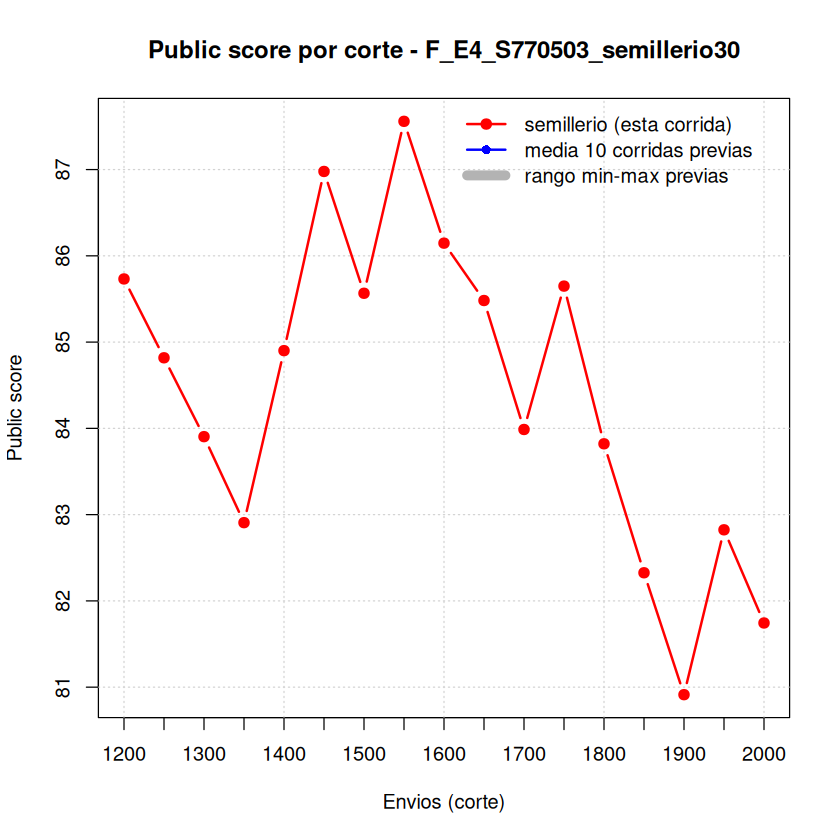

In [63]:
# ==========================================
# GRAFICO PARA ELEGIR EL CORTE - GRUPO B
# ==========================================

# resumen de las 10 corridas anteriores (un solo modelo por semilla)
# AJUSTAR la ruta si el archivo esta en otra carpeta
arch_historico <- file.path(
  ruta_final, "exp_GrupoB_Final_resumen_kaggle_por_corte.csv"
)

tb_comp <- tb_puntajes[, list(
  envios,
  public_semillerio = publicScore,
  private_semillerio = privateScore
)]

if (file.exists(arch_historico)) {
  hist <- fread(arch_historico)
  tb_comp <- merge(
    tb_comp,
    hist[, list(
      envios,
      hist_media = public_media, hist_sd = public_sd,
      hist_min = public_min, hist_max = public_max
    )],
    by = "envios", all.x = TRUE
  )
} else {
  cat("No se encontro el historico:", arch_historico, "\n")
  tb_comp[, c("hist_media", "hist_sd", "hist_min", "hist_max") := NA_real_]
}

setorder(tb_comp, envios)
tb_comp[, dif_vs_hist := public_semillerio - hist_media]

fwrite(tb_comp, file = "comparacion_cortes.csv", sep = ",", na = "")
print(tb_comp)

graficar_cortes <- function() {
  x <- tb_comp$envios
  yr <- range(
    c(tb_comp$public_semillerio, tb_comp$hist_min, tb_comp$hist_max),
    na.rm = TRUE
  )

  plot(x, tb_comp$public_semillerio, type = "n", ylim = yr, xaxt = "n",
    xlab = "Envios (corte)", ylab = "Public score",
    main = paste("Public score por corte -", PARAM$id_ejecucion)
  )
  axis(1, at = x)
  grid()

  if (any(!is.na(tb_comp$hist_media))) {
    polygon(
      c(x, rev(x)), c(tb_comp$hist_min, rev(tb_comp$hist_max)),
      col = adjustcolor("grey70", 0.5), border = NA
    )
    lines(x, tb_comp$hist_media, col = "blue", lwd = 2, type = "b", pch = 16)
  }

  lines(x, tb_comp$public_semillerio, col = "red", lwd = 2, type = "b", pch = 19)

  legend("topright", bty = "n",
    legend = c("semillerio (esta corrida)", "media 10 corridas previas",
               "rango min-max previas"),
    col = c("red", "blue", "grey70"),
    lwd = c(2, 2, 8), pch = c(19, 16, NA)
  )
}

png("grafico_cortes_kaggle.png", width = 1000, height = 600, res = 120)
graficar_cortes()
invisible(dev.off())

graficar_cortes()

In [64]:
format(Sys.time(), "%a %b %d %X %Y")

[1] "Thu Nov 05 01:22:19 2026"